In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns

In [ ]:
#Cargamos archivos
comex = pd.read_csv("DataComex-import-export-españa.csv", sep=";", decimal=",")
puerto = pd.read_csv("datosPuerto.csv", decimal=",")

In [ ]:
comex.head()

,flujo_codigo,flujo_nombre,periodo_anio,periodo_mes,pais_codigo,pais_nombre,taric,euros,kilos
0,E,Exportación,2023,NaN,4,Alemania,1,2.582091e+07,12311373.85
1,E,Exportación,2023,NaN,4,Alemania,2,2.474109e+08,61880984.91
2,E,Exportación,2023,NaN,4,Alemania,3,7.407838e+07,9079254.08
3,E,Exportación,2023,NaN,4,Alemania,4,5.266799e+07,13319346.91
4,E,Exportación,2023,NaN,4,Alemania,5,3.385100e+07,13454767.14


In [ ]:
puerto.head()

,Unnamed: 0,FECHA,AGRUP_MERCANCIA,TIPO_MERCANCIA,PARTIDA_ARANCELARIA,TIPO_ENVASE,CARGA_DESCARGA,PAIS_ORIGEN,PAIS_FINAL,PESO_KILOS
0,0,2007-01-22,1,1,2709A,4,D,IQ,ES,138283515
1,1,2007-01-22,1,1,2709A,4,D,RU,ES,101154523
2,2,2007-01-22,1,2,2710A,4,C,ES,ES,38831068
3,3,2007-01-22,1,2,2710A,4,C,ES,US,56224084
4,4,2007-01-22,1,2,2710A,4,D,RU,ES,33789198


In [ ]:
#Cambiamos la fecha a datetime y ponemos solo el año
puerto['FECHA'] = pd.to_datetime(puerto['FECHA'])
puerto['FECHA'] = puerto['FECHA'].dt.year


In [ ]:
puerto.head()

,Unnamed: 0,FECHA,AGRUP_MERCANCIA,TIPO_MERCANCIA,PARTIDA_ARANCELARIA,TIPO_ENVASE,CARGA_DESCARGA,PAIS_ORIGEN,PAIS_FINAL,PESO_KILOS
0,0,2007,1,1,2709A,4,D,IQ,ES,138283515
1,1,2007,1,1,2709A,4,D,RU,ES,101154523
2,2,2007,1,2,2710A,4,C,ES,ES,38831068
3,3,2007,1,2,2710A,4,C,ES,US,56224084
4,4,2007,1,2,2710A,4,D,RU,ES,33789198


In [ ]:
print(comex.info())
print("")
print(comex.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49368 entries, 0 to 49367
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   flujo_codigo  49368 non-null  object 
 1   flujo_nombre  49368 non-null  object 
 2   periodo_anio  49368 non-null  int64  
 3   periodo_mes   0 non-null      float64
 4   pais_codigo   49368 non-null  int64  
 5   pais_nombre   49368 non-null  object 
 6   taric         49368 non-null  int64  
 7   euros         49368 non-null  float64
 8   kilos         49368 non-null  float64
dtypes: float64(3), int64(3), object(3)
memory usage: 3.4+ MB
None

(49368, 9)


In [ ]:
print(puerto.info())
print("")
print(puerto.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1366811 entries, 0 to 1366810
Data columns (total 10 columns):
 #   Column               Non-Null Count    Dtype 
---  ------               --------------    ----- 
 0   Unnamed: 0           1366811 non-null  int64 
 1   FECHA                1366811 non-null  int32 
 2   AGRUP_MERCANCIA      1366811 non-null  int64 
 3   TIPO_MERCANCIA       1366811 non-null  int64 
 4   PARTIDA_ARANCELARIA  1366811 non-null  object
 5   TIPO_ENVASE          1366811 non-null  int64 
 6   CARGA_DESCARGA       1366811 non-null  object
 7   PAIS_ORIGEN          1366599 non-null  object
 8   PAIS_FINAL           1366017 non-null  object
 9   PESO_KILOS           1366811 non-null  int64 
dtypes: int32(1), int64(5), object(4)
memory usage: 99.1+ MB
None

(1366811, 10)


In [ ]:
#Filtramos para que el periodo de años sea del 2009 al 2019(es hasta 2019 poprque el dataset de euskadi solo llega hasta 2019)
comex_filtrado = comex[(comex["pais_nombre"] == "Países Bajos") & (comex["periodo_anio"] >= 2009) & (comex["periodo_anio"] <= 2019)]

In [ ]:
comex_filtrado.head()

,flujo_codigo,flujo_nombre,periodo_anio,periodo_mes,pais_codigo,pais_nombre,taric,euros,kilos
38455,E,Exportación,2019,NaN,3,Países Bajos,1,1.531194e+07,629695.99
38456,E,Exportación,2019,NaN,3,Países Bajos,2,1.182433e+08,44078159.41
38457,E,Exportación,2019,NaN,3,Países Bajos,3,3.889445e+07,7216917.79
38458,E,Exportación,2019,NaN,3,Países Bajos,4,6.818900e+07,45443813.88
38459,E,Exportación,2019,NaN,3,Países Bajos,5,7.801363e+06,7030591.46


In [ ]:
#Agrupamos los kilos por años y separamos en exportaciones y importaciones
total_exp_es = (comex_filtrado[comex_filtrado["flujo_nombre"] == "Exportación"].groupby("periodo_anio")["kilos"].sum())

total_imp_es = (comex_filtrado[comex_filtrado["flujo_nombre"] == "Importación"].groupby("periodo_anio")["kilos"].sum())

In [ ]:
total_exp_es

periodo_anio
2009    4.559499e+09
2010    4.798761e+09
2011    4.861719e+09
2012    5.530430e+09
2013    5.194177e+09
2014    6.231726e+09
2015    6.723958e+09
2016    7.303106e+09
2017    8.379631e+09
2018    8.281130e+09
2019    8.209378e+09
Name: kilos, dtype: float64

In [ ]:
total_imp_es

periodo_anio
2009    5.616894e+09
2010    5.724174e+09
2011    5.167226e+09
2012    5.252961e+09
2013    4.439218e+09
2014    4.476626e+09
2015    5.210852e+09
2016    5.077312e+09
2017    4.756788e+09
2018    5.028079e+09
2019    5.721122e+09
Name: kilos, dtype: float64

In [ ]:
#FIltramos solo paises bajos
puerto_paisesbajos = puerto[(puerto["PAIS_FINAL"] == "NL") | (puerto["PAIS_ORIGEN"] == "NL")]

In [ ]:
#Filtramos solo paises bajos y españa
exp_puerto = puerto_paisesbajos[(puerto_paisesbajos["PAIS_ORIGEN"] == "ES") & (puerto_paisesbajos["PAIS_FINAL"] == "NL")]

imp_puerto = puerto_paisesbajos[(puerto_paisesbajos["PAIS_ORIGEN"] == "NL") & (puerto_paisesbajos["PAIS_FINAL"] == "ES")]

In [ ]:
#agrupamos los kilos pòr años
imp_puerto = imp_puerto.groupby("FECHA")["PESO_KILOS"].sum()
exp_puerto =exp_puerto.groupby("FECHA")["PESO_KILOS"].sum()

In [ ]:
#Filtramos solo de 2009 a 2019
exp_puerto=exp_puerto.loc[2009:2019]

In [ ]:
imp_puerto=imp_puerto.loc[2009:2019]

In [ ]:
exp_puerto

FECHA
2009     366543925
2010     410957443
2011     754842617
2012     540914746
2013     851701657
2014     940298629
2015     595610110
2016     844578531
2017     951613421
2018     971474553
2019    1154433286
Name: PESO_KILOS, dtype: int64

In [ ]:
imp_puerto

FECHA
2009     826407028
2010    1096816180
2011     786733730
2012     925922346
2013     732426144
2014     785162500
2015     790342418
2016     690588712
2017     683978612
2018     696356457
2019     831587812
Name: PESO_KILOS, dtype: int64

In [ ]:
#Calculamos la importancia del puerto de bilbao en las exportaciones con respecto a españa
porcentaje_exp = (exp_puerto / total_exp_es) * 100

In [ ]:
porcentaje_exp

FECHA
2009     8.039126
2010     8.563825
2011    15.526249
2012     9.780699
2013    16.397240
2014    15.088895
2015     8.858028
2016    11.564649
2017    11.356269
2018    11.731184
2019    14.062372
dtype: float64

In [ ]:
#Calculamos la importancia del puerto de bilbao en las importaciones con respecto a españa
porcentaje_imp = (imp_puerto / total_imp_es) * 100

In [ ]:
porcentaje_imp

FECHA
2009    14.712882
2010    19.161125
2011    15.225457
2012    17.626675
2013    16.498989
2014    17.539159
2015    15.167240
2016    13.601464
2017    14.379002
2018    13.849354
2019    14.535397
dtype: float64

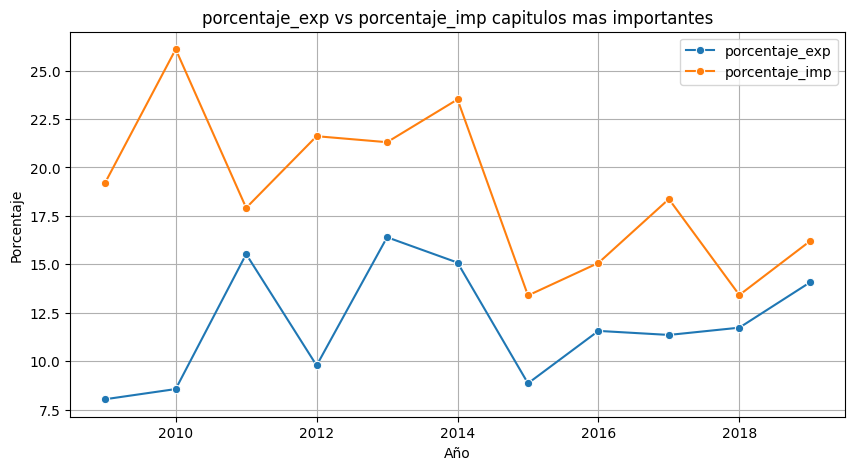

In [ ]:
#Ponemos los resultados para hacer un grafico
años = [2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019]

porcentaje_imp_puerto = [8.039126, 8.563825, 15.526249, 9.780699, 16.397240,15.088895, 8.858028, 11.564649, 11.356269, 11.731184, 14.062372]

porcentaje_exp_puerto = [19.220859, 26.099254, 17.913981, 21.611057, 21.301688,23.508977, 13.392031, 15.073102, 18.368581, 13.416463, 16.188671]

plt.figure(figsize=(10,5))
sns.lineplot(x=años, y=porcentaje_exp, marker="o", label="porcentaje_exp")
sns.lineplot(x=años, y=porcentaje_exp_puerto, marker="o", label="porcentaje_imp")

plt.title("porcentaje_exp vs porcentaje_imp capítulos más importantes")
plt.xlabel("Año")
plt.ylabel("Porcentaje")
plt.grid(True)
plt.legend()
plt.show()